<a href="https://colab.research.google.com/github/maharanis6/klasifikasi-kedalaman-gempa/blob/main/Maharani_Sabila_AI_Fundamental_Coding_Challenge_Workbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Fundamentals Coding Challenge

**Nama:**  Maharani Sabila

**Tanggal:** 17-10-2026

**Link Dataset yang digunakan:** [Earthquake Kaggle](https://www.kaggle.com/datasets/kekavigi/earthquakes-in-indonesia)

**Latar Belakang**:
Indonesia berada di pertemuan antara lempeng bumi yang menyebabkan gempa sering terjadi. Selain magnitudo yang sering kali dibahas, mengetahui kedalaman pusat gempa juga tak kalah penting. Pada kekuatan yang sama, gempa yang dangkal lebih terasa dan lebih berpotensi merusak permukaan dibanding gempa dalam.

**Tujuan Analisis**: Apakah kita bisa menebak kedalaman gempa berdasarkan dari lokasinya (lintang dan bujur) dan besaran magnitudonya?

**Batasan Masalah**: Model tidak memprediksi kapan terjadinya gempa, model ini hanya mengelompokkan gempa yang sudah tercatat berdasarkan kedalamannya.

---
## Daftar Isi
1. [Challenge 1 - Data Exploration](#challenge-1)
2. [Challenge 2 - Machine Learning](#challenge-2)
3. [Challenge 3 - Prediction](#challenge-3)
4. [Challenge 4 - Integrasi Gemini API](#challenge-4)
5. [Challenge 5 - Responsible AI Reflection](#challenge-5)

---


Catatan terkait Dataset:
1. Silahkan gunakan dataset yang sesuai dengan ide mini demo day kelompok kamu atau dapat dicari di open source platform lainnya seperti:
  a. https://www.kaggle.com/datasets
  b. https://www.bps.go.id/
  c. https://data.worldbank.org
  d. https://data.cityofchicago.org/
  e. https://djpk.kemenkeu.go.id/portal/data/apbd
  f. https://archive.ics.uci.edu/datasets
  

## Setup Awal
Jalankan cell di bawah ini terlebih dahulu sebelum mengerjakan challenge apa pun.

In [ ]:
# Import library dasar
import sys
sys.path.append('..')  # agar bisa import dari folder src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from dotenv import load_dotenv

from sklearn.model_selection import train_test_split

%matplotlib inline
RANDOM_STATE = 1082026  # gunakan nilai ini di semua fungsi yang membutuhkan random_state

print('Setup berhasil. Library siap digunakan.')

Setup berhasil. Library siap digunakan.


---
<a id='challenge-1'></a>
## Challenge 1 - Data Exploration (Pandas)

**Tujuan:** Memahami struktur dataset, mendeteksi missing values, dan menampilkan insight awal.

### Instruksi
- Muat dataset ke dalam DataFrame
- Tampilkan 5 baris pertama, info(), dan describe()
- Cek missing values dan duplikasi data
- Buat minimal 2 visualisasi dari pilihan berikut: distribusi fitur, histogram, scatter plot, correlation heatmap, atau box plot
- Tuliskan insight dalam sel markdown berdasarkan pertanyaan yang diberikan

In [ ]:
# Soal 1.1: Muat dataset
# Masukkan path dataset yang sesuai (contoh: '../data/nama_dataset.csv')
df = pd.read_csv('katalog_gempa.csv')
print(f'Dataset shape: {df.shape}')

Dataset shape: (92887, 13)


In [ ]:
print(f"\nDataset Overview:")
df.head(5)


Dataset Overview:


,tgl,ot,lat,lon,depth,mag,remark,strike1,dip1,rake1,strike2,dip2,rake2
0,2008/11/01,21:02:43.058,-9.18,119.06,10,4.9,Sumba Region - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN
1,2008/11/01,20:58:50.248,-6.55,129.64,10,4.6,Banda Sea,NaN,NaN,NaN,NaN,NaN,NaN
2,2008/11/01,17:43:12.941,-7.01,106.63,121,3.7,Java - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN
3,2008/11/01,16:24:14.755,-3.30,127.85,10,3.2,Seram - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN
4,2008/11/01,16:20:37.327,-6.41,129.54,70,4.3,Banda Sea,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Soal 1.2: Informasi umum dataset
print('=== Dataset Info ===')
df.info()

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92887 entries, 0 to 92886
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   tgl      92887 non-null  object 
 1   ot       92887 non-null  object 
 2   lat      92887 non-null  float64
 3   lon      92887 non-null  float64
 4   depth    92887 non-null  int64  
 5   mag      92887 non-null  float64
 6   remark   92887 non-null  object 
 7   strike1  2735 non-null   float64
 8   dip1     2735 non-null   float64
 9   rake1    2735 non-null   float64
 10  strike2  2735 non-null   float64
 11  dip2     2735 non-null   float64
 12  rake2    2735 non-null   float64
dtypes: float64(9), int64(1), object(3)
memory usage: 9.2+ MB


In [ ]:
print('\n=== Dataset Describe ===')
print(df.describe())


=== Dataset Describe ===
                lat           lon         depth           mag      strike1  \
count  92887.000000  92887.000000  92887.000000  92887.000000  2735.000000   
mean      -3.404577    119.159707     49.009399      3.592788   170.142852   
std        4.354584     10.833202     76.761070      0.834042    88.359267   
min      -11.000000     94.020000      2.000000      1.000000     0.000000   
25%       -7.885000    113.170000     10.000000      3.000000   107.550000   
50%       -2.910000    121.160000     16.000000      3.500000   144.600000   
75%        0.140000    126.900000     54.000000      4.200000   217.500000   
max        6.000000    142.000000    750.000000      7.900000   359.200000   

              dip1        rake1      strike2         dip2        rake2  
count  2735.000000  2735.000000  2735.000000  2735.000000  2735.000000  
mean     60.202121    30.358062   197.450303    56.576344    35.250018  
std      19.699252    99.957906   118.920519    21.2

In [ ]:
print('\n=== Missing Values ===')
print(df.isnull().sum())


=== Missing Values ===
tgl            0
ot             0
lat            0
lon            0
depth          0
mag            0
remark         0
strike1    90152
dip1       90152
rake1      90152
strike2    90152
dip2       90152
rake2      90152
dtype: int64


In [ ]:
print('\n=== Persentase Missing ===')
print((df.isnull().mean() * 100).round(1))


=== Persentase Missing ===
tgl         0.0
ot          0.0
lat         0.0
lon         0.0
depth       0.0
mag         0.0
remark      0.0
strike1    97.1
dip1       97.1
rake1      97.1
strike2    97.1
dip2       97.1
rake2      97.1
dtype: float64


In [ ]:
print('\n=== Duplicated Rows ===')
print(f'Total: {df.duplicated().sum()}')


=== Duplicated Rows ===
Total: 0


# **Pembersihan Data**



*   Mengubah teks tanggal menjadi tipe tanggal.
*   Membuang kolom mekanisme sesar (strike1, dip1, rake1, strake2, dip2, rake2) karena banyak yang kosong, sehingga tidak bisa diandalkan.



In [ ]:
# Mengubah teks tanggal menjadi tipe tanggal, lalu diambil tahunnya saja
df['tgl'] = pd.to_datetime(df['tgl'], format='%Y/%m/%d')
df['tahun'] = df['tgl'].dt.year

# Membuang kolom mekanisme sesar karena banyak yang kosong
kolom_sesar = ['strike1', 'dip1', 'rake1', 'strike2', 'dip2', 'rake2']
df = df.drop(columns=kolom_sesar)

print(df.shape)
df.head()

(92887, 8)


,tgl,ot,lat,lon,depth,mag,remark,tahun
0,2008-11-01,21:02:43.058,-9.18,119.06,10,4.9,Sumba Region - Indonesia,2008
1,2008-11-01,20:58:50.248,-6.55,129.64,10,4.6,Banda Sea,2008
2,2008-11-01,17:43:12.941,-7.01,106.63,121,3.7,Java - Indonesia,2008
3,2008-11-01,16:24:14.755,-3.30,127.85,10,3.2,Seram - Indonesia,2008
4,2008-11-01,16:20:37.327,-6.41,129.54,70,4.3,Banda Sea,2008


In [ ]:
# Soal 1.3: Visualisasi data (minimal 2 grafik)
#
# GUIDE: Pilih 2-3 jenis visualisasi dari berikut:
# 1. Distribution/Histogram
# 2. Scatter plot (relationship antar features)
# 3. Correlation heatmap
# 4. Box plot (per kategori jika ada)
# 5. Pie chart (untuk categorical data)


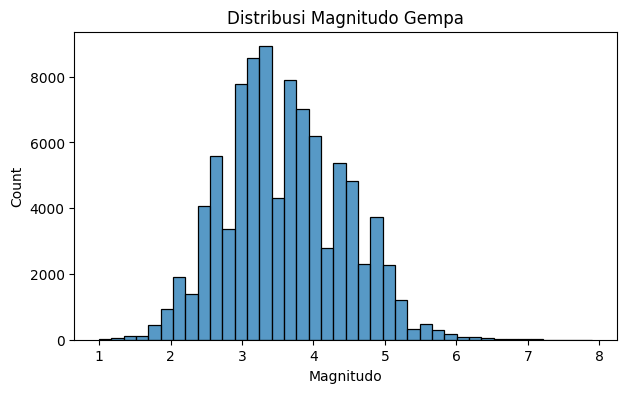

In [ ]:
# Grafik 1: Distribusi magnitudo
plt.figure(figsize=(7, 4))
sns.histplot(df['mag'], bins=40)
plt.title('Distribusi Magnitudo Gempa')
plt.xlabel('Magnitudo')
plt.show()

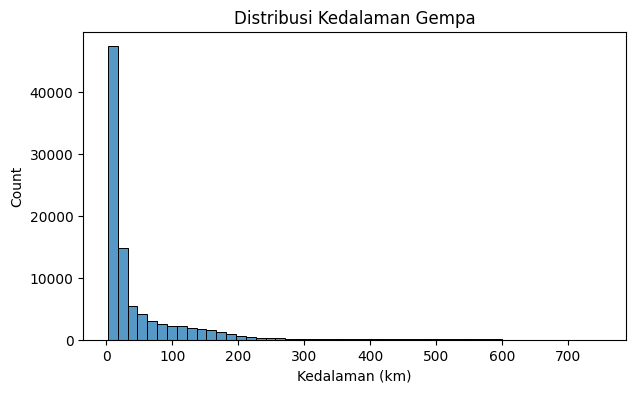

In [ ]:
# Grafik 2: Distribusi kedalaman
plt.figure(figsize=(7, 4))
sns.histplot(df['depth'], bins=50)
plt.title('Distribusi Kedalaman Gempa')
plt.xlabel('Kedalaman (km)')
plt.show()

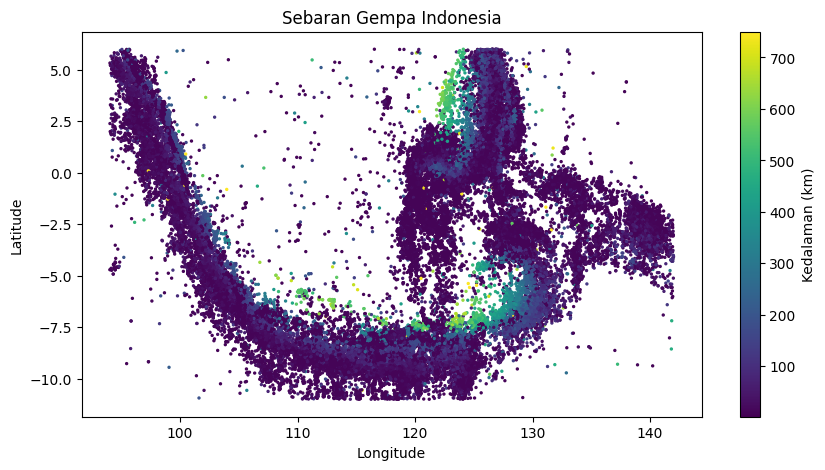

In [ ]:
# Grafik 3: Peta sebaran gempa, warna = kedalaman
plt.figure(figsize=(10, 5))
plt.scatter(df['lon'], df['lat'], c=df['depth'], s=2, cmap='viridis')
plt.colorbar(label='Kedalaman (km)')
plt.title('Sebaran Gempa Indonesia')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

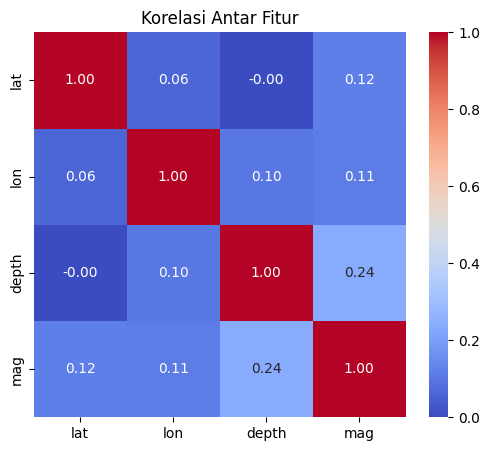

In [ ]:
# Grafik 4: Korelasi antar fitur angka
plt.figure(figsize=(6, 5))
sns.heatmap(df[['lat', 'lon', 'depth', 'mag']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Antar Fitur')
plt.show()


**Insight Challenge 1:**

1.   **Karakteristik**: data terdiri dari 92.887 baris dengan 13 kolom. Terdiri dari text (tgl, ot, remark), koordinat (lat, lon), ukuran gempa(depth, mag), dan 6 kolom sesar.
2.   **Data Quality**: tidak ada duplikat, 6 kolom sesar memiliki missing values masing-masing 90.152 atau dibuat dalam presentase sekitar 97%.
3.   **Distribusi Fitur**: Distribusi depth sangat miring ke kanan dengan rata-rata 49 km jauh diatas median 16 km dan nilai maksimum mencapai 750 km. Sedangkan, mag menghasilkan mean 3,59 dan median 3,5.
4.   **Korelasi**: Korelasi antar fitur cenderung lemah depth-mag 0,24. Sedangkan lat-depth hampir nol. Pada peta menunjukkan kedalaman (grafik 3 warna hijau sampai kuning) bergantung lokasi hanya saja polanya melengkung, bukan lurus sehingga tidak tertangkap korelasi linear, sehingga model ini lebih cocok non-linear.





---
<a id='challenge-2'></a>
## Challenge 2 - Machine Learning (Scikit-learn)

**Tujuan:** Melatih dan mengevaluasi model Machine Learning menggunakan Scikit-learn, kemudian membandingkan beberapa pendekatan untuk menentukan model yang paling sesuai dengan dataset dan tujuan prediksi Anda.

### Instruksi
- Pisahkan fitur (X) dan target (y) dari dataset
- **PENTING:** Tentukan variabel target yang ingin diprediksi
- Tentukan jenis masalah Machine Learning berdasarkan target:
  - **Binary Classification** — target memiliki 2 kelas
  - **Multiclass Classification** — target memiliki lebih dari 2 kelas
  - **Regression** — target berupa nilai numerik yang ingin diprediksi
- Bagi data menjadi train/test set (gunakan `random_state=RANDOM_STATE`)
- Pilih dan **bandingkan minimal 2 algoritma** yang sesuai dengan jenis masalah Anda
- Latih model dan evaluasi performanya menggunakan metrik yang sesuai
- Pilih satu model final berdasarkan hasil eksperimen dan alasan yang jelas
- Simpan model final terlatih ke file untuk Challenge 3

> **Catatan penting:** Contoh model di notebook ini adalah panduan, bukan pilihan yang wajib diikuti. Anda bebas mengeksplorasi algoritma lain selama dapat menjelaskan alasan pemilihannya.

### Kriteria Dataset untuk Challenge 2

Pilih dataset yang memungkinkan Anda melakukan **eksperimen Machine Learning** dan menjawab sebuah pertanyaan prediktif.

Dataset yang dipilih sebaiknya:
- Memiliki **target/label yang jelas** dan dapat diprediksi
- Memiliki **fitur yang relevan** untuk digunakan sebagai input model
- Memiliki jumlah observasi yang cukup untuk melakukan training dan testing
- Memiliki kualitas data yang cukup baik untuk dianalisis, atau memiliki masalah data yang dapat Anda tangani melalui preprocessing
- Memungkinkan Anda membandingkan minimal dua model Machine Learning

### Jenis masalah yang dapat dipilih

Anda **bebas memilih jenis masalah sesuai karakteristik dataset**, misalnya:

| Jenis masalah | Contoh target | Contoh algoritma |
|---|---|---|
| **Binary Classification** | 0/1, Yes/No, Positive/Negative | Logistic Regression, Decision Tree, Random Forest, SVM |
| **Multiclass Classification** | A/B/C, Rendah/Sedang/Tinggi | Logistic Regression, Decision Tree, Random Forest, Gradient Boosting |
| **Regression** | Harga, jumlah, skor, pendapatan | Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor |

> **Tidak ada satu jenis masalah atau algoritma yang diwajibkan.** Pilih pendekatan yang paling sesuai dengan dataset dan pertanyaan yang ingin Anda jawab.

### Evaluasi Model

Metrik evaluasi harus disesuaikan dengan jenis masalah dan karakteristik data.

**Untuk Classification**, Anda dapat menggunakan:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Jika distribusi kelas tidak seimbang (*class imbalance*), **jangan menggunakan accuracy sebagai satu-satunya dasar untuk menilai performa model**.

**Untuk Regression**, Anda dapat menggunakan:
- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² (R-squared)

> **Yang dinilai bukan seberapa banyak model yang Anda coba, tetapi kemampuan Anda menjelaskan alasan pemilihan model, hasil evaluasi, perbandingan model, dan keterbatasannya.**

# Menentukan Target

Target baru dinamakan kelas_kedalaman dari kolom depth.

Berdasarkan beberapa sumber dapat dikategorikan dalam:

| Kelas | Rentang kedalaman |
|---|---|
| **Dangkal** | sampai 60 km |
| **Menengah** | 61 km sampai 300 km |
| **Dalam** | Lebih dari 300 km |




In [ ]:
# Soal 2.1: Definisikan fitur (X) dan target (y)

df['kelas_kedalaman'] = pd.cut(
    df['depth'],
    bins=[0, 60, 300, 1000],
    labels=['Dangkal', 'Menengah', 'Dalam']
)

TARGET = 'kelas_kedalaman'
FITUR = ['lat', 'lon', 'mag']

X = df[FITUR]
y = df[TARGET]

print('=== Fitur (X) ===')
print(list(X.columns))

print('\n=== Target (y) ===')
print(f'Nama target: {TARGET}')
print(f'Jumlah nilai unik: {y.nunique()}')

print('\n=== Distribusi target ===')
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

PROBLEM_TYPE = 'classification'
print(f'\nJenis masalah: {PROBLEM_TYPE}')

=== Fitur (X) ===
['lat', 'lon', 'mag']

=== Target (y) ===
Nama target: kelas_kedalaman
Jumlah nilai unik: 3

=== Distribusi target ===
kelas_kedalaman
Dangkal     71443
Menengah    19853
Dalam        1591
Name: count, dtype: int64
kelas_kedalaman
Dangkal     0.769
Menengah    0.214
Dalam       0.017
Name: proportion, dtype: float64

Jenis masalah: classification


### Panduan Menentukan Jenis Masalah

Gunakan karakteristik **target (`y`)**, bukan jumlah fitur, untuk menentukan jenis masalah.

- Jika target berupa **kategori/kelas** → **Classification**
  - 2 kelas → Binary Classification
  - >2 kelas → Multiclass Classification
- Jika target berupa **nilai numerik yang ingin diprediksi** → **Regression**

**Tuliskan jawaban Anda:**

> Target yang saya prediksi adalah: `kelas_kedalaman`  
> Jenis masalah saya adalah: `multiclass classification`  
> Alasan: `Target berupa kategori dengan 3 kelas (Dangkal, Menengah, Dalam), bukan angka kontinu`

---

In [ ]:
# Soal 2.2: Split data train/test

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print('\nJumlah data train:', len(X_train))
print('Jumlah data test :', len(X_test))


Jumlah data train: 74309
Jumlah data test : 18578


In [ ]:
# Soal 2.3: Latih model

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)

model_alternatif = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_baseline.fit(X_train, y_train)
model_alternatif.fit(X_train, y_train)
print('Kedua model selesai dilatih.')

Kedua model selesai dilatih.


## 2.4 Evaluasi dan Perbandingan Model

Evaluasi semua model menggunakan **metrik yang sesuai dengan jenis masalah**.

### Jika Classification

Gunakan beberapa metrik yang relevan:
- **Accuracy** — proporsi prediksi yang benar secara keseluruhan
- **Precision** — proporsi prediksi positif yang benar
- **Recall** — proporsi kasus positif yang berhasil ditemukan
- **F1-score** — keseimbangan precision dan recall
- **Confusion Matrix** — melihat jenis kesalahan prediksi

Jika data memiliki **class imbalance**, jangan hanya melihat accuracy.

### Jika Regression

Gunakan beberapa metrik yang relevan:
- **MAE** — rata-rata besar kesalahan absolut
- **RMSE** — memberi penalti lebih besar pada error yang besar
- **R²** — seberapa baik model menjelaskan variasi target

> Jangan hanya mencari angka tertinggi. Pahami apa arti setiap metrik dalam konteks masalah Anda.

In [ ]:
# Soal 2.4: Evaluasi model

from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# Tebakan acuan: selalu menjawab kelas yang paling banyak
acuan = y_test.value_counts(normalize=True).max()
print(f'Akurasi tebakan acuan (selalu pilih kelas terbanyak): {acuan:.3f}\n')

hasil = []
for nama, model in [('Logistic Regression', model_baseline),
                    ('Random Forest', model_alternatif)]:
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    hasil.append({
        'Model': nama,
        'Akurasi Train': accuracy_score(y_train, pred_train),
        'Akurasi Test': accuracy_score(y_test, pred_test),
        'Macro F1 Test': f1_score(y_test, pred_test, average='macro')
    })
    print(f'===== {nama} =====')
    print(classification_report(y_test, pred_test))

tabel = pd.DataFrame(hasil).round(3)
tabel

Akurasi tebakan acuan (selalu pilih kelas terbanyak): 0.769

===== Logistic Regression =====
              precision    recall  f1-score   support

       Dalam       0.00      0.00      0.00       318
     Dangkal       0.77      1.00      0.87     14289
    Menengah       0.38      0.01      0.01      3971

    accuracy                           0.77     18578
   macro avg       0.38      0.33      0.29     18578
weighted avg       0.67      0.77      0.67     18578

===== Random Forest =====
              precision    recall  f1-score   support

       Dalam       0.86      0.60      0.71       318
     Dangkal       0.87      0.97      0.92     14289
    Menengah       0.80      0.52      0.63      3971

    accuracy                           0.86     18578
   macro avg       0.85      0.70      0.75     18578
weighted avg       0.86      0.86      0.85     18578



,Model,Akurasi Train,Akurasi Test,Macro F1 Test
0,Logistic Regression,0.768,0.769,0.293
1,Random Forest,0.888,0.865,0.753


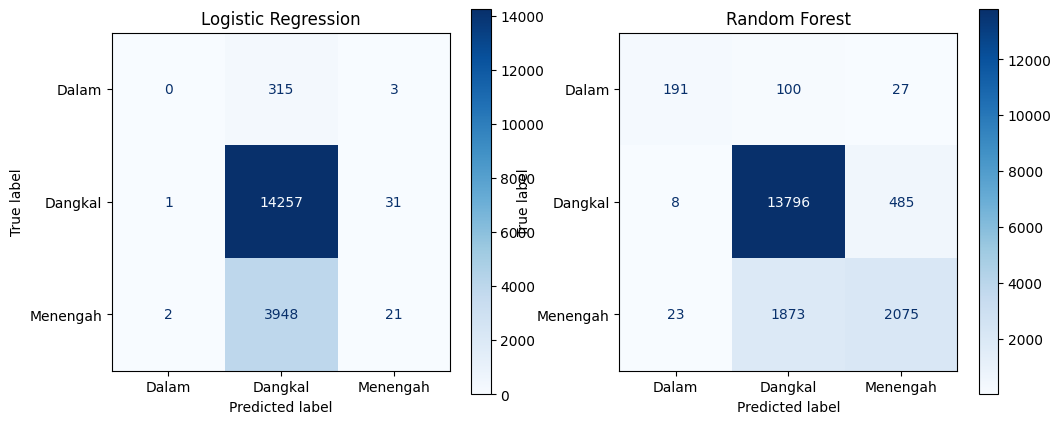

In [ ]:
# Confusion matrix kedua model
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nama, model) in zip(axes, [('Logistic Regression', model_baseline),
                                    ('Random Forest', model_alternatif)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap='Blues')
    ax.set_title(nama)
plt.show()

### Analisis Confusion Matrix — khusus Classification

Jika Anda mengerjakan classification, analisis confusion matrix untuk melihat jenis kesalahan model.

Untuk binary classification:

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | TN | FP |
| **Actual 1** | FN | TP |

Untuk multiclass classification, confusion matrix akan memiliki lebih dari dua kelas.

Jawab:
- Kelas mana yang paling mudah dikenali?
- Kelas mana yang paling sering salah diprediksi?
- Apakah false positive atau false negative lebih penting dalam use case Anda?
- Apa konsekuensi kesalahan tersebut?

Jika Anda mengerjakan regression, bagian confusion matrix dapat dilewati.

**Jawaban**:

| Random Forest | Predicted Dalam | Predicted Dangkal | Predicted Menengah | Total | Benar |
|---|---|---|---|---|---:|
| **Asli Dalam** | 191 | 100 | 27 | 318 | 60% |
| **Asli Dangkal** |  8 | 13.796 | 485 | 14.289 | 97% |
| **Asli Menengah** |  23 | 1.873 | 2.075 | 3.971 | 52% |

**Pada Logistic Regression**, hampir semua gempa ditebak Dangkal: 315 + 14.257 + 3.948 = 18.520 dari 18.578 gempa test (99,7%).



*   **Paling mudah dikenali**: Dangkal. Pada Random Forest, 13.796 dari 14.289 gempa dangkal tertebak benar (sekitar 97%), meskipun sebagian karena kelas ini mendominasi data (sekitar 77%). Pada Logistic Regression, angka tinggi itu semu karena hampir semua gempa ditebak Dangkal sebanyak 14.257.
* **Paling sering salah**: Menengah. Pada Random Forest dari 3.971 gempa menengah, hanya 2.075 yang benar. Sebanyak 1.896 (sekitar 48%) salah, dan hampir semuanya (1.873) dikira Dangkal. Kelas Dalam juga sering terlewat (127 dari 318, sekitar 40%), tetapi jumlahnya kecil karena datanya sedikit. Pada Logistic Regression, kesalahannya lebih parah: dari 3.971 gempa menengah hanya 21 yang benar, dan dari 318 gempa dalam tidak ada satu pun.
* **FP atau FN**: Dengan menjadikan Dangkal sebagai kelas berisiko, dapat menilai false negative (gempa dangkal ditebak lebih dalam, 493 kasus) lebih penting karena dapat meremehkan potensi dampak di permukaan. False positive (gempa menengah/dalam ditebak Dangkal, 1.973 kasus) lebih sering terjadi tetapi cenderung konservatif, meski membuat pola gempa dalam sulit dikenali.
* **Konsekuensi**: Kesalahan tersebut dapat menimbulkan penilaian dampak yang keliru, sehingga hasil model hanya layak untuk analisis awal dan edukasi, bukan dasar keputusan keselamatan. Informasi resmi tetap bersumber dari BMKG.

### Overfitting / Underfitting

Bandingkan performa pada data training dan testing.

Perhatikan:
- Apakah performa training jauh lebih baik daripada testing?
- Apakah model terlalu sederhana sehingga performanya rendah pada keduanya?
- Apakah terdapat indikasi overfitting atau underfitting?

Jelaskan berdasarkan hasil eksperimen, bukan hanya berdasarkan definisi teori.

**Jawaban**:
| Model | Train | Test | Selisih |
|---|---:|---:|---:|
| **Logistic Regression** | 0,768 | 0,769 | -0,001 |
| **Random Forest** | 0,888 | 0,865 | 0,023 |


* **Logistic Regression**: skor train dan test sama-sama rendah dan hampir identik, sama dengan tebakan acuan. Ini underfitting: modelnya terlalu sederhana untuk pola lokasi yang melengkung.
*   **Random Forest**: train sedikit lebih tinggi dari test (selisih sekitar 2,3 poin). Ada overfitting ringan, tapi masih wajar, dan skor test tetap tinggi.

### Feature Importance / Model Interpretation

Jika model Anda mendukung interpretasi fitur, analisis fitur yang paling berpengaruh.

Contoh:
- Random Forest → `feature_importances_`
- Linear/Logistic Regression → koefisien
- Model lain → gunakan metode interpretasi yang sesuai

> **Catatan:** Feature importance tidak otomatis berarti hubungan sebab-akibat.

Jika model tidak memiliki feature importance secara langsung, Anda dapat menggunakan permutation importance atau menjelaskan keterbatasan interpretasinya.

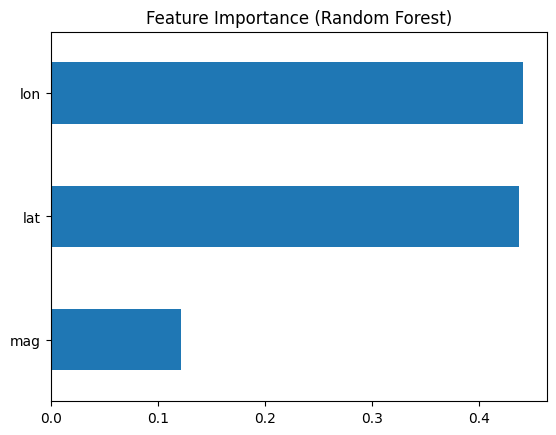

lon    0.441
lat    0.437
mag    0.122
dtype: float64


In [ ]:
pentingnya = pd.Series(model_alternatif.feature_importances_, index=FITUR).sort_values()
pentingnya.plot(kind='barh', title='Feature Importance (Random Forest)')
plt.show()
print(pentingnya.sort_values(ascending=False).round(3))

## 2.5 Memilih Model Final

Setelah membandingkan model, pilih **satu model final** untuk digunakan pada Challenge 3.

Pertimbangkan:
- Performa pada metrik utama
- Keseimbangan beberapa metrik
- Interpretabilitas
- Kompleksitas model
- Kecepatan
- Kebutuhan preprocessing
- Risiko overfitting
- Konteks penggunaan

**Model final yang saya pilih:** `Random Forest Classifier`

**Alasan:**
Saya memilih Random Forest sebagai model final karena performanya jauh lebih baik pada metrik utama, yaitu macro F1 sebesar 0,753 dibandingkan 0,293 pada Logistic Regression. Logistic Regression hanya mencapai akurasi 0,769 yang sama dengan tebakan acuan (selalu memilih Dangkal) dan tidak mengenali satu pun gempa Dalam (recall 0,00), sedangkan Random Forest mencapai akurasi 0,865 dengan recall kelas Dalam 0,60 dan Menengah 0,52. Hal ini sejalan dengan temuan di Challenge 1 bahwa pola kedalaman gempa mengikuti lokasi secara melengkung dan tidak linear, sehingga model non-linear lebih sesuai. Risiko overfitting tergolong rendah karena selisih akurasi train (0,888) dan test (0,865) hanya sekitar 2,3 poin. Dari sisi praktis, Random Forest tidak memerlukan penskalaan fitur dan proses pelatihannya masih cepat untuk data sebesar ini. Kekurangannya, model ini lebih sulit dijelaskan dibanding Logistic Regression dan masih melewatkan sekitar 40% gempa Dalam serta hampir separuh gempa Menengah, sehingga hasilnya sebaiknya tidak dipakai sebagai satu-satunya dasar keputusan.

In [ ]:
# Soal 2.5: Simpan model final

import joblib

model_final = model_alternatif
joblib.dump(model_final, 'model.pkl')
print('Model tersimpan sebagai model.pkl')

Model tersimpan sebagai model.pkl


**Insight Challenge 2:**

Analisis hasil eksperimen berdasarkan pertanyaan berikut (min. 5-7 kalimat):

1. **Jenis Masalah**: Apa target yang diprediksi dan mengapa masalah Anda termasuk classification atau regression?
2. **Pemilihan Model**: Model apa saja yang dibandingkan? Mengapa model tersebut dipilih?
3. **Performa Model**: Bagaimana hasil masing-masing model berdasarkan metrik yang digunakan?
4. **Kesalahan Model**: Jika classification, apa yang terlihat dari confusion matrix? Jika regression, bagaimana pola error atau nilai MAE/RMSE?
5. **Overfitting/Underfitting**: Apakah terdapat indikasi overfitting atau underfitting?
6. **Feature Importance / Interpretasi**: Fitur mana yang paling berpengaruh jika dapat dianalisis?
7. **Model Final**: Model mana yang akhirnya dipilih dan mengapa?
8. **Langkah Improvement**: Apa yang dapat dilakukan untuk meningkatkan performa model?

**Jawaban**:

1.   **Jenis Masalah**:
Target yang saya prediksi adalah kelas_kedalaman, yaitu kategori kedalaman pusat gempa (Dangkal, Menengah, Dalam) yang dibuat dari kolom depth. Karena target berupa kategori dengan tiga kelas, bukan angka kontinu, masalah ini termasuk multiclass classification. Fitur yang digunakan adalah lat, lon, dan mag, sedangkan depth sengaja tidak dimasukkan agar tidak terjadi data leakage. Distribusi kelasnya tidak seimbang: Dangkal sekitar 77%, Menengah 21%, dan Dalam 1,7%.

2.   **Pemilihan Model**:
Saya membandingkan dua model, yaitu Logistic Regression sebagai baseline dan Random Forest sebagai model alternatif. Logistic Regression dipilih karena sederhana, cepat, dan mudah diinterpretasi. Random Forest dipilih karena mampu menangkap pola non-linear, sesuai temuan di Challenge 1 bahwa kedalaman gempa berkaitan dengan lokasi secara melengkung dan korelasi liniernya lemah.

3. **Performa Model**:
Karena data tidak seimbang, saya membandingkan hasil dengan tebakan acuan (selalu memilih Dangkal) yang akurasinya 0,769. Logistic Regression hanya mencapai akurasi 0,769 dengan macro F1 0,293 dan recall kelas Dalam 0,00, sehingga tidak lebih baik dari tebakan acuan. Random Forest mencapai akurasi 0,865 dan macro F1 0,753, dengan recall Dalam 0,60, Menengah 0,52, dan Dangkal 0,97. Karena itu macro F1 saya jadikan metrik utama, bukan akurasi.

4. **Kesalahan Model**:
Pada confusion matrix Logistic Regression, hampir semua gempa ditebak sebagai Dangkal (misalnya 3.948 dari 3.971 gempa Menengah), yang menunjukkan model hanya menebak kelas mayoritas. Pada Random Forest, kelas Dangkal paling mudah dikenali (13.796 dari 14.289 benar). Kesalahan terbesar ada pada kelas Menengah: 1.873 gempa (sekitar 47%) salah dikira Dangkal, dan 100 dari 318 gempa Dalam juga dikira Dangkal. Sehingga kesalahan yang paling berisiko adalah gempa dangkal yang ditebak lebih dalam (sekitar 493 kasus), karena bisa meremehkan potensi dampak di permukaan.

5. **Overfitting/Underfitting**:
Logistic Regression mengalami underfitting: akurasi train (0,768) dan test (0,769) sama-sama rendah dan setara tebakan acuan, artinya modelnya terlalu sederhana untuk pola lokasi yang melengkung. Random Forest memiliki akurasi train 0,888 dan test 0,865, dengan selisih sekitar 2,3 poin. Ini menunjukkan overfitting ringan yang masih wajar, karena performa pada data test tetap tinggi.

5. **Feature Importance / Interpretasi**:
Berdasarkan feature importance Random Forest, lon (0,44) dan lat (0,44) paling banyak dipakai model, sedangkan mag jauh lebih kecil (0,12). Artinya, model lebih mengandalkan lokasi daripada kekuatan gempa untuk menebak kedalaman, sesuai pola jalur gempa dalam pada peta sebaran. Namun feature importance tidak membuktikan hubungan sebab-akibat, hanya menunjukkan fitur yang paling banyak dipakai model.

6. **Model Final**:
Saya memilih Random Forest sebagai model final. Alasannya, macro F1-nya (0,753) jauh lebih tinggi dibanding Logistic Regression (0,293), ia mampu mengenali kelas langka, dan risiko overfitting-nya rendah. Kekurangannya, model ini lebih sulit dijelaskan dibanding Logistic Regression dan masih melewatkan sekitar 40% gempa Dalam serta hampir separuh gempa Menengah.

7. **Langkah Improvement**:
Saya bisa mencoba class_weight='balanced' pada Random Forest. Langkah lain yang bisa dicoba adalah menambah fitur seperti remark atau tahun, menyetel hyperparameter (misalnya max_depth), mencoba model boosting, atau mengumpulkan lebih banyak data gempa dalam.

---
<a id='challenge-3'></a>
## Challenge 3 - Prediction

**Tujuan:** Menggunakan model yang telah dilatih untuk memprediksi data baru yang belum pernah dilihat.

### Instruksi
- Muat kembali model yang sudah disimpan di Challenge 2
- Buat 2-3 contoh data baru dengan fitur yang sama dengan X
- Lakukan prediksi dan tampilkan hasilnya; jika model mendukung `predict_proba`, tampilkan probability/confidence scores

In [ ]:
# Soal 3.1: Muat model (jika perlu, jika di-run terpisah dari Challenge 2)
import joblib

model = joblib.load('model.pkl')
print('✓ Model loaded')

✓ Model loaded


In [ ]:
# Soal 3.2: Buat data baru untuk diprediksi
# Kolom dan urutannya HARUS sama dengan X: lat, lon, mag

data_baru = pd.DataFrame({
    'lat': [-6.5, -9.0, 1.2],
    'lon': [129.6, 107.5, 124.8],
    'mag': [4.6, 5.0, 3.5]
})
print('Data baru untuk diprediksi:')
print(data_baru)

Data baru untuk diprediksi:
   lat    lon  mag
0 -6.5  129.6  4.6
1 -9.0  107.5  5.0
2  1.2  124.8  3.5


In [ ]:
# Soal 3.3: Lakukan prediksi dan tampilkan hasil

hasil_prediksi = model.predict(data_baru)
print('\nHasil Prediksi:', hasil_prediksi)

try:
    hasil_proba = model.predict_proba(data_baru)
    print('\nPrediction Probability:')
    for i, proba in enumerate(hasil_proba):
        print(f'Sample {i+1}:')
        for label, probability in zip(model.classes_, proba):
            print(f'  Class {label}: {probability:.2%}')
except AttributeError:
    print('\nModel ini tidak mendukung predict_proba.')


Hasil Prediksi: ['Menengah' 'Dangkal' 'Dangkal']

Prediction Probability:
Sample 1:
  Class Dalam: 2.01%
  Class Dangkal: 6.86%
  Class Menengah: 91.13%
Sample 2:
  Class Dalam: 0.78%
  Class Dangkal: 73.12%
  Class Menengah: 26.10%
Sample 3:
  Class Dalam: 0.64%
  Class Dangkal: 65.21%
  Class Menengah: 34.15%


---
<a id='challenge-4'></a>
## Challenge 4 - Integrasi Gemini API

**Tujuan:** Menggunakan Gemini API untuk menjelaskan hasil prediksi dengan bahasa natural yang mudah dipahami.
- Install Google AI library: `pip install google-generativeai python-dotenv`

In [ ]:
!pip install -q google-genai

In [ ]:
# Soal 4.1: Setup Gemini API
client = None
try:
    from google import genai
    try:
        from google.colab import userdata
        API_KEY = userdata.get('GEMINI_API_KEY')
    except Exception:
        API_KEY = os.getenv('GEMINI_API_KEY')

    if not API_KEY:
        print('ERROR: GEMINI_API_KEY tidak ditemukan. Cek langkah persiapan di atas.')
    else:
        client = genai.Client(api_key=API_KEY)
        print('Gemini API berhasil dikonfigurasi.')
except ImportError:
    print('Library google-genai belum terpasang. Jalankan sel instalasi di atas.')

Gemini API berhasil dikonfigurasi.


In [ ]:
# Soal 4.2: Susun prompt dan minta penjelasan dari Gemini

prompt = f"""
Sebuah model machine learning memprediksi kategori Kedalaman gempa bumi di Indonesia
berdasarkan lokasi (lintang, bujur) dan magnitudo.

Data baru yang diprediksi:
{data_baru.to_string()}

Hasil prediksi dari model:
{list(hasil_prediksi)}

Penjelasan fitur:
- lat: lintang lokasi gempa (negatif = selatan khatulistiwa)
- lon: bujur lokasi gempa
- mag: magnitudo (kekuatan gempa)

Kategori: Dangkal (<=60 km), Menengah (61-300 km), Dalam (>300 km).

Tugas: Jelaskan dengan bahasa awam, singkat, dan ramah mengapa model memprediksi
kategori tersebut. Jelaskan juga apa artinya bagi masyarakat, dan ingatkan bahwa
ini bukan prediksi kapan gempa terjadi dan bukan pengganti informasi resmi BMKG.

Jelaskan dengan bahasa yang mudah dipahami (bukan teknis) mengapa model
menentukan hasil tersebut berdasarkan nilai-nilai input yang ada.
Jelaskan juga implikasi atau interpretasi dari hasil model dalam konteks nyata.
"""

In [ ]:
# Jalankan prediksi Gemini
NAMA_MODEL_GEMINI = 'gemini-2.5-flash'

if client is None:
    print('Client Gemini belum siap. Selesaikan tahap 4.1 dulu.')
else:
    try:
        response = client.models.generate_content(model=NAMA_MODEL_GEMINI, contents=prompt)
        penjelasan = response.text
        print('=== Penjelasan dari Gemini ===')
        print(penjelasan)
    except Exception as e:
        print(f'Error: {e}')

=== Penjelasan dari Gemini ===
Baik, mari kita jelaskan hasil prediksi ini dengan bahasa yang mudah dipahami:

---

Halo! Bayangkan model machine learning ini seperti seorang ahli yang sudah melihat ribuan, bahkan jutaan, data gempa bumi di Indonesia sebelumnya. Dia belajar dari setiap gempa: di mana lokasinya (lintang, bujur) dan seberapa kuat gempa itu (magnitudo). Dari situ, dia mengenali pola-pola khusus.

Ketika ada data gempa baru, seperti yang kita punya, si ahli ini akan membandingkan lokasi dan kekuatan gempa itu dengan pola-pola yang sudah dia pelajari, lalu menebak: "Oh, berdasarkan lokasi dan kekuatannya ini, kemungkinan besar kedalamannya masuk kategori *ini*."

**Inilah arti prediksi model tersebut untuk gempa-gempa yang Anda berikan:**

1.  **Gempa pertama (di lokasi -6.5, 129.6 dengan kekuatan 4.6) diprediksi: 'Menengah'**
    *   **Mengapa demikian?** Model melihat lokasi ini (yang berada di sekitar wilayah Indonesia Timur) dan magnitudo 4.6. Berdasarkan data-data gemp

# **Contoh Jawaban Gemini**:
=== Penjelasan dari Gemini ===
Tentu, mari kita jelaskan dengan bahasa yang mudah dimengerti!

---

**Bagaimana Model "Berpikir" (Penjelasan Singkat)**

Bayangkan model Machine Learning ini seperti seorang pengamat yang sudah mempelajari ribuan data gempa bumi di Indonesia di masa lalu. Ia melihat banyak kejadian gempa dan mencatat di mana letaknya (lintang, bujur), seberapa kuatnya (magnitudo), dan di kedalaman berapa gempa itu terjadi.

Dari semua data itu, model belajar bahwa kombinasi dari lokasi (lintang, bujur) dan kekuatan (magnitudo) gempa seringkali berkaitan dengan seberapa dalam gempa itu terjadi. Jadi, saat ada data gempa baru, model akan membandingkannya dengan "pengalamannya" di masa lalu dan menebak kedalamannya berdasarkan pola yang pernah ia lihat.

**Mengapa Model Memprediksi Demikian untuk Setiap Kasus?**

1.  **Gempa di (-6.5, 129.6) dengan magnitudo 4.6 diprediksi 'Menengah'**
    *   **Penjelasan Model:** Model melihat bahwa untuk lokasi di sekitar sana dengan kekuatan gempa sekitar 4.6, pola gempa di masa lalu lebih sering menunjukkan kedalaman 'Menengah' (61-300 km). Jadi, model memilih kategori tersebut.

2.  **Gempa di (-9.0, 107.5) dengan magnitudo 5.0 diprediksi 'Dangkal'**
    *   **Penjelasan Model:** Meskipun kekuatannya sedikit lebih besar dari contoh pertama, model mengidentifikasi bahwa di lokasi ini, pola gempa di masa lalu dengan kekuatan yang mirip cenderung terjadi di kedalaman 'Dangkal' (<=60 km).

3.  **Gempa di (1.2, 124.8) dengan magnitudo 3.5 diprediksi 'Dangkal'**
    *   **Penjelasan Model:** Sama seperti kasus kedua, untuk lokasi ini dengan magnitudo 3.5, model menemukan pola di data historis bahwa gempa lebih sering terjadi di kedalaman 'Dangkal'.

**Apa Artinya Bagi Kita Masyarakat?**

*   **Gempa Dangkal (<=60 km):** Ini berarti gempa terjadi relatif dekat dengan permukaan tanah. Getarannya seringkali terasa lebih kuat di area sekitar pusat gempa dan berpotensi menimbulkan dampak kerusakan yang lebih besar secara lokal.
*   **Gempa Menengah (61-300 km):** Gempa jenis ini terasa lebih lemah di permukaan dibandingkan gempa dangkal dengan kekuatan yang sama, namun bisa dirasakan di area yang lebih luas. Kerusakan yang ditimbulkan biasanya tidak seberat gempa dangkal, kecuali kekuatannya sangat besar.
*   **Gempa Dalam (>300 km):** Gempa ini terjadi sangat jauh di bawah permukaan. Meskipun kekuatannya besar, efek guncangannya di permukaan biasanya sangat lemah dan jarang menimbulkan kerusakan, meskipun bisa dirasakan di wilayah yang sangat luas.

**Penting untuk Diingat (Bukan Prediksi dan Bukan Pengganti Informasi Resmi!)**

*   **Ini BUKAN prediksi kapan gempa akan terjadi.** Model ini hanya menebak seberapa dalam gempa tersebut, *jika* gempa terjadi di lokasi dan dengan kekuatan tersebut.
*   **Ini BUKAN informasi resmi.** Selalu jadikan informasi dari Badan Meteorologi, Klimatologi, dan Geofisika (BMKG) sebagai acuan utama Anda untuk informasi gempa bumi yang akurat dan terkini.

Jadi, model ini seperti memberikan gambaran awal berdasarkan data masa lalu, tapi keputusan dan informasi resmi tetap dari BMKG ya! Selalu waspada dan ikuti petunjuk keselamatan dari pihak berwenang.

---
<a id='challenge-5'></a>
## Challenge 5 - Responsible AI Reflection

**Tujuan:** Merefleksikan aspek etika dan tanggung jawab dalam penggunaan AI/ML.

### Instruksi
Jawab SEMUA pertanyaan reflektif berikut dalam sel markdown di bawah. Setiap jawaban minimal 3-5 kalimat, gunakan format yang rapi (bullet points, paragraf, dll).

**Jawaban Reflection (Jawab semua 5 pertanyaan):**

### 1. Bias Data
**Pertanyaan:** Apakah dataset yang digunakan berpotensi bias? Apakah data representatif untuk semua kelompok demografis (gender, usia, etnis, lokasi, dll)? Jelaskan konsekuensi jika ada bias.

**Jawaban:**
* Data bisa berpotensi memiliki bias dalam cakupan geografis, periode pengamatan, dan kelengkapan catatan kejadian gempa.
* Dataset ini berfokus pada kejadian gempa bukan data individu berdasarkan representasi gender, usia, dan etnis tertentu.
* Jika terdapat bias, model dapat menghasilkan klasifikasi kedalaman yang kurang akurat pada wilayah atau kelompok data tertentu. Sehingga perlu dipahami cakupan dataset dan bandingkan dengan sumber data resmi misalnya dari data aktual BMKG sebagai badan resmi yang menanganinya di Indonesia.

---

### 2. Keterbatasan Model
**Pertanyaan:** Dalam kondisi apa model ini bisa memberikan prediksi yang salah atau menyesatkan? Apakah ada edge cases atau input yang tidak valid?

**Jawaban:**
* Model dibuat dengan tujuan mengklasifikasikan kedalaman gempa dalam kategori tertentu bukan memprediksi kapan gempa terjadi.
* Untuk prediksi yang salah pada ksusu ini kategori dalam ternyata datanya sangat sedikit dan menengah paling sering terlewat.
* Model juga berpotensi memberikan hasil yang tidak sesuai jika menerima input di luar cakupan data pelatihan atau nilai yang tidak masuk akal berdasarkan definisi fitur dan sumber data.

---

### 3. Transparansi AI Generatif
**Pertanyaan:** Penjelasan di Challenge 4 dihasilkan oleh AI (Gemini). Apakah pengguna akhir PERLU TAHU bahwa penjelasan ini dari AI? Apa risikonya jika tidak transparansi?

**Jawaban:**
* Pengguna perlu tahu bahwa penjelasan pada challenge 4 berasal dari AI Generatif yakni,Gemini. Gemini di sini bertugas dalam menjelaskan hasil klasifikasi kedalaman gempa dalam bahasa yang lebih mudah dipahami, bukan memvalidasi kinerja model atau menggantikan penilaian ahli kebumian. * Risikonya, teks yang terdengar meyakinkan bisa dianggap informasi resmi walaupun keliru. Sehingga penjelasan AI Generative ini perlu memiliki batasan yang jelas, bisa juga disertai untuk mengarahkan ke halaman lain sumber resmi seperti BMKG untuk mendapatkan informasi aktual.

---

### 4. Dampak Sosial
**Pertanyaan:** Jika model ini digunakan dalam skala besar/nyata (misalnya di aplikasi mobile, rumah sakit, atau perusahaan), dampak apa yang mungkin timbul (positif & negatif)? Siapa saja yang bisa terpengaruh?

**Jawaban:**
* Positif: Bisa menjadi bahan edukasi kebencanaan dan analisis awal mengenai pengelompokkan kedalaman gempa berdasarkan data historis. Model juga bisa menjadi sarana pembelajaran masyarakat untuk memahami karakteristik kejadian gempa dan cara membaca data bencana.
* Negatif: disalahartikan sebagai alat peringatan dini sehingga menimbulkan kepanikan jika tidak disertai pemeriksaan lebih lanjut.
* Yang dapat terpengaruh: masyarakat, pemerintah daerah, peneliti, media. Sehingga sistem juga perlu menegaskan penelitian ini hanya sebagai prototipe pembelajaran bukan pengganti informasi resmi maupun peringatan dini gempa yang terjadi.
---

### 5. Rekomendasi Responsible AI
**Pertanyaan:** Apa langkah/strategi yang bisa diambil untuk membuat sistem ini lebih bertanggung jawab (responsible AI)? Pikir tentang: transparency, fairness, accountability, security, dll.

**Jawaban:**
* Jika sistem yang dibuat bisa lebih bertanggung jawab sumber asli dataset, periode pengamatan, cakupan geigrafis dan keterbatasan data perlu dijelaskan secara transparan.
* Penelitian masih terbatas pada interpretasi AI maka perlu melibatkan ahli geologi/kebumian atau pihak yang berkompeten serta bandingkan dengan data resmi BMKG sebelum hasil ini dikembangkan di luar pembelajaran.
* Secara keamanan karena menggunakan Gemini API maka perlu menjaga kerahasiaan API Key yang ada. Di sini menggunakan Google Collab sebagai tools-nya maka API Key dapat memanfaatkan Colab Secrets environment variables dan tidak dibagikan secara publik.

---

---
## Kesimpulan Akhir

**Ringkasan Pengerjaan:**
_(Tuliskan ringkasan keseluruhan, meliputi:)_
- Apa yang telah Anda pelajari dari setiap challenge?
- Kendala/challenges yang Anda hadapi dan bagaimana mengatasinya?
- Insight utama atau "aha moment" dari project ini?
- Apa yang ingin Anda pelajari lebih lanjut?

**Jawaban**:

- **Melalui Challenge ini saya mempelajari**: mulai dari pengolahan data, eksplorasi data, pembangunan model Machine Learning, evaluasi model, prediksi baru, integrasi Gemini API, serta penerapan prinsip responsible AI. Untuk setiap challenge memiliki tingkat kesulitan tersendiri dan memahami hasil data juga cukup membutuhkan pemahaman lebih sebagai pemula seperti saya.
- **Dalam mengatasi kendala**: terutama mendapatkan dataset yang sesuai saya perlu mencari dari banyak sumber agar dataset masih berkorelasi dengan tema mini demoday. Untuk pengerjaan dan pemahaman setiap instruksi juga membutuhkan pemahaman lebih lama, sehingga pengerjaan proyek ini sedikit membutuhkan waktu lebih lama.
- **Ternyata**: pada data yang dihasilkan memiliki akurasi tampak tinggi (77%), tetapi hanya setara tebakan acuan dan gagal mengenali kategori tertentu seperti gempa dalam.Sehingga perlu pemahaman pentingnya distribusi kelas, confusion matrix, dan evaluasi setiap kategori sebelum menarik kesimpulan.
- **Setelah menyelesaikan tugas ini**, saya menambah ilmu bahwa AI Generative bisa digunakan membantu menjelaskan hasil teknis dengan bahasa yang mudah dipahami. Kedepannya, saya ingin mengetahui lebih dalam mengenai karakteristik kedalaman gempa, faktor yang mempengaruhi dampak guncangan di permukaan, serta menyampaikan informasi kebencanaan secara akurat yang mudah dipahami masyarakat. Selain itu, saya ingin memperdalam mbelajar Machine Learning yang bisa dimanfaatkan secara bertanggung jawab untuk mendukung edukasi terutama mengenai aksi iklim.